# [수업] 실습 ② 요약 생성 — 텍스트·표·이미지를 검색 가능한 요약문으로


지난 시간에 PDF에서 꺼낸 **텍스트 / 표 / 이미지**를, 검색에 쓸 수 있는 **요약문(색인 카드)** 으로 바꿉니다.

```
텍스트 ──┐
  표   ──┼──▶  요약문 생성  ──▶  검색용 색인(색인 카드)
이미지 ──┘      LLM / VLM
```

## 수업 진행 방식

- 코드 셀에는 **주석만** 있습니다. 강사 화면을 보며 주석 아래에 코드를 **함께 작성**합니다.
- 각 단계마다 **📖 개념 → ⌨️ 따라 치기 → ✅ 확인** 순서로 진행합니다.
- 셀은 위에서부터 순서대로 실행합니다 (`Shift + Enter`).

## 오늘의 학습 목표

1. LCEL 파이프(`|`)로 **요약 체인**을 구성할 수 있다
2. LLM으로 **텍스트·표 요약**을 일괄(batch) 생성할 수 있다
3. 이미지를 **Base64**로 변환해 **VLM**에 전달할 수 있다
4. 요약 품질을 **육안으로 검증**하고 비용(토큰)을 측정할 수 있다

## 💸 비용 안내

`gpt-4o-mini` 기준 PDF 한 편에 수십 원 수준입니다. 다만,
- 요약 셀을 **반복 실행하면 그만큼 비용이 다시** 나갑니다
- `max_concurrency`를 함부로 올리면 `RateLimitError`에 걸립니다

---
# Part 1. 준비

## 0. API 키 불러오기

### 📖 개념
- API 키는 `.env` 파일에 두고 `python-dotenv`로 읽어 옵니다. 코드에 직접 적지 않습니다.
- 키 전체를 `print()` 하지 않습니다. 화면 공유나 스크린샷 한 번이면 유출됩니다. **앞 7자 + 뒤 4자**만 확인합니다.

In [19]:
# ⌨️ 0-1. os, time, pickle, Path(pathlib), load_dotenv(dotenv) 를 임포트합니다.
import os
import time
import pickle
from pathlib import Path
from dotenv import load_dotenv

# ⌨️ 0-2. PROJECT_ROOT 를 정합니다.
#        현재 폴더 이름이 "invest" 또는 "practice" 이면 상위 폴더, 아니면 현재 폴더
# cwd() -> 현재 위치 반환
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name in ["invest", "practice"] else Path.cwd()

# ⌨️ 0-3. PROJECT_ROOT / ".env" 파일을 load_dotenv 로 읽습니다.
# / -> 하위
load_dotenv(PROJECT_ROOT / ".env")      # 임시로 캐싱해옴

# ⌨️ 0-4. 환경변수 "OPENAI_API_KEY" 를 openai_api_key 에 담습니다.
openai_api_key = os.getenv("OPENAI_API_KEY")    # OPENAI_AI_KEY 상수, 변하지 않음, 공용 변수 / openai_api_key -> 변수로 변화하는 부분 변경

# ⌨️ 0-5. 키가 없으면 ValueError 를 발생시킵니다.
if not openai_api_key:
    # raise -> 발생시키다. 예외처리 발생
    raise ValueError("환경변수 OPENAI_API_KEY 가 없습니다. .env 파일을 확인하세요.")

# ⌨️ 0-6. 키를 "앞 7자 + ... + 뒤 4자" 형태로만 출력합니다.
print(f"API Key: {openai_api_key[:7]} ... {openai_api_key[-4:]}")



API Key: sk-proj ... Vq0A


In [20]:
# ⌨️ 0-7. 키가 실제로 유효한지 확인합니다.
#        openai 패키지에서 OpenAI, AuthenticationError 를 임포트하고
#        OpenAI().models.list() 를 호출해 AuthenticationError 가 나면 안내 문구와 함께 중단합니다.
from openai import OpenAI, AuthenticationError

try:
    OpenAI(api_key = openai_api_key).models.list()
    print("환경변수 OPENAI_API_KEY 가 유효합니다.")
except AuthenticationError:
    raise ValueError("환경변수 OPENAI_API_KEY 가 없습니다. .env 파일을 확인하세요.")


환경변수 OPENAI_API_KEY 가 유효합니다.


> ✅ **확인:** `API 키 로드 완료: sk-proj...abcd` 형태로 출력되고, 유효성 확인에서 오류가 없어야 합니다.

## 1. 지난 시간 결과 복원

### 📖 개념
- PDF 추출(`hi_res`)은 2~3분이 걸립니다. 그래서 지난 시간 마지막에 **pickle**로 저장해 두었습니다.
- pickle = 파이썬 객체를 그대로 **냉동 보관**했다가 **해동**해서 쓰는 도구입니다.
- `FileNotFoundError`가 나면 지난 시간 노트북의 **저장 셀**을 실행하지 않은 것입니다.

In [21]:
# ⌨️ 1-1. PROJECT_ROOT / "data" / "processed" / "extracted.pkl" 경로를 pkl_path 에 담습니다.
pk1_path = PROJECT_ROOT / "data" / "processed" / "extracted.pkl"

# ⌨️ 1-2. 파일을 바이너리 읽기 모드("rb")로 열어 pickle.load 로 data 에 불러옵니다.
with open(pk1_path, "rb") as f:
    data = pickle.load(f)       # pickle.load() -> 객체로 되살리라는 뜻

# ⌨️ 1-3. data 딕셔너리에서 texts, tables, texts_2k_token 을 꺼냅니다.
texts = data["texts"]
tables = data["tables"]
texts_2k_token = data["texts_2k_token"]

# ⌨️ 1-4. 각 리스트의 개수를 출력합니다.
print(f"texts 개수: {len(texts)}")
print(f"tables 개수: {len(texts)}")
print(f"texts_2k_token 개수: {len(texts_2k_token)}")

# ⌨️ 1-5. 지난 시간에 이미지를 저장한 폴더를 figures_dir 로 잡고 존재 여부를 출력합니다.
#        (지난 시간: PDF 폴더 아래 "figures" → PROJECT_ROOT / "data" / "figures")
figures_dir = PROJECT_ROOT / "data" / "figures"
print(f"figures_dir 존재 여부: {figures_dir.exists()}")



texts 개수: 31
tables 개수: 31
texts_2k_token 개수: 80
figures_dir 존재 여부: True


> ✅ **확인:** 세 리스트 개수가 지난 시간과 같고, 이미지 폴더 `존재: True` 여야 합니다. `False`면 본인 PDF 폴더 이름에 맞게 경로를 고칩니다.

---
# Part 2. 텍스트·표 요약 (LLM)

## 2. 요약 체인 만들기

### 📖 개념 — LCEL 파이프는 컨베이어 벨트
왼쪽 작업대의 결과물이 오른쪽 작업대의 재료가 됩니다.

```
{"element": lambda x: x}  →  prompt  →  model  →  StrOutputParser()
       입력 포장              템플릿 적용   LLM 호출      문자열로 꺼내기
```

| 칸 | 받는 것 | 내보내는 것 |
| --- | --- | --- |
| `{"element": lambda x: x}` | 문자열 | `{"element": 문자열}` 딕셔너리 |
| `prompt` | 딕셔너리 | 완성된 프롬프트 |
| `model` | 프롬프트 | `AIMessage` 객체 |
| `StrOutputParser()` | `AIMessage` | 순수 문자열 |

### 📖 개념 — `.batch()` 와 `max_concurrency`
- `.invoke(x)` 는 한 건, `.batch([x1, x2, ...])` 는 여러 건을 **동시에** 처리합니다.
- `max_concurrency=5` → 동시에 최대 5건만 요청. 너무 높이면 `RateLimitError`.
- `temperature=0` → 같은 입력에 최대한 같은 출력 (요약은 창의성보다 **일관성**이 중요)

In [22]:
# ⌨️ 2-1. StrOutputParser, ChatPromptTemplate, ChatOpenAI 를 임포트합니다.
#        (langchain_core.output_parsers / langchain_core.prompts / langchain_openai)
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

# ⌨️ 2-2. generate_text_summaries(texts, tables, summarize_texts=False) 함수를 정의합니다.
def generate_text_summaries(texts, tables, summarize_texts = False):

#   ⌨️ (1) 한국어 요약 프롬프트 문자열을 작성합니다. 반드시 {element} 자리표시자를 포함합니다.
#          내용: "표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 /
#                 검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"
    prompt_text_kor = """
                    당신은 표와 텍스트를 요약하여 검색에 활용할 수 있도록 돕는 도우미입니다.
                    이 요약본들은 임베딩되어 원본 텍스트나 표 요소를 검색하는 데 사용될 것입니다.
                    주어진 표나 텍스트의 내용을 검색에 최적화된 간결한 요약으로 작성해주세요.
                    원문이 영어여도 반드시 한국어로 요약하세요.
                    요약할 표 또는 텍스트: {element}"""
#     prompt_text_en = """
#                     You are an assistant tasked with summarizing tables and text for retrieval.
#                     # These summaries will be embedded and used to retrieve the raw text or table elements.
#                     # Give a concise summary of the table or text that is well optimized for retrieval.
#                     # Table or text: {element}"""

#   ⌨️ (2) ChatPromptTemplate.from_template 으로 prompt 를 만듭니다.
    prompt = ChatPromptTemplate.from_template(prompt_text_kor)

#   ⌨️ (3) ChatOpenAI 로 model 을 만듭니다. (temperature=0, model="gpt-4o-mini")
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

#   ⌨️ (4) 컨베이어 벨트 4칸을 | 로 연결해 summarize_chain 을 만듭니다.
    #   요약을 위한 체인 = 입력 포장 + 프롬프트 + LLM + 출력 파서
    summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

#   ⌨️ (5) text_summaries, table_summaries 빈 리스트를 만듭니다.
    text_summaries = []
    table_summaries = []

#   ⌨️ (6) texts 가 있고 summarize_texts 가 True 면 → batch 로 요약 (max_concurrency 5)
#          texts 는 있지만 summarize_texts 가 False 면 → 원문을 그대로 사용
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    elif texts:
        text_summaries = texts
#   ⌨️ (7) tables 가 있으면 → batch 로 요약 (max_concurrency 5)
    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 1})
        

#   ⌨️ (8) text_summaries, table_summaries 를 반환합니다.
    return text_summaries, table_summaries

# ⌨️ 2-3. "generate_text_summaries 정의 완료" 를 출력합니다.
print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


## 3. 텍스트·표 요약 실행

> ⏱️ API 호출로 **1~3분** 걸립니다. 💸 **한 번만** 실행하세요.

In [23]:
# ⌨️ 3-1. 시작 시각을 기록합니다.
start = time.time()

# ⌨️ 3-2. texts_2k_token 과 tables 를 넣어 generate_text_summaries 를 호출합니다.
#        텍스트도 요약해야 하므로 summarize_texts=True
text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)

# ⌨️ 3-3. 소요 시간, 텍스트 요약 수, 표 요약 수를 출력합니다.
print(f"요약 완료 — {time.time() - start:.1f}초 소요")
print(f"텍스트 요약 수 => {len(text_summaries)}")
print(f"표 요약 수 => {len(table_summaries)}")



요약 완료 — 137.7초 소요
텍스트 요약 수 => 80
표 요약 수 => 4


## 4. 요약 결과 확인

### 📖 개념 — 압축률
요약문 길이 ÷ 원본 길이. 너무 높으면 요약이 안 된 것, 너무 낮으면 정보가 빠졌을 수 있습니다.

In [24]:
# ⌨️ 4-1. 구분선과 함께 texts_2k_token[0] 의 앞 300자를 출력합니다.
print("--" * 60)
print("[원본] text_2k_token[0] - 앞 300자")
print("--" * 60)
print(texts_2k_token[0][:300])

# ⌨️ 4-2. 구분선과 함께 text_summaries[0] 전체를 출력합니다.
print("--" * 60)
print("[원본] text_summaries[0]")
print("--" * 60)
print(text_summaries[0])
print()

# ⌨️ 4-3. 원본 글자 수, 요약 글자 수, 압축률(%)을 출력합니다.
print("--" * 60)
origin = len(texts_2k_token[0])
summ = len(text_summaries[0])
print(f"압축률: {origin}자 -> {summ} 자 ({summ / origin * 100:.1f}%)")

"""
요약길이  / 원본길이 ==> 숫자가 작을수록 더 많이 줄였다.
압축률이 낮춘다. => 10% -> 5% => 요약을 더 짧게
압축률을 높인다. => 10% -> 30% => 요약을 더 길게, 세부 내용까지 남겨달라
------------------------------------------------------
ex. 경제 보고서 관련 -> 핵심 키워드(경제, 주제, 상세 예측)이 남겨지는게 좋음
파이프라인을 만들 때 조율해야하는 부분
------------------------------------------------------

압축률의 기준을 뭐라고 생각했는지 -> 실제 질문으로 검색이 잘 되는지 기준이 되어야 합니다.

"""

------------------------------------------------------------------------------------------------------------------------
[원본] text_2k_token[0] - 앞 300자
------------------------------------------------------------------------------------------------------------------------
Uo , “i ~@ ap an ZEAE S24 Y, Y Yl 7 G ~Lolm4 247 Ay “UY UiMl tlle Y; Y G WY hin Y, Y, Y; NG “Wii y, YW, vy —Yyp Y Cone WWW, al SS YUM 0, Mio, filuy, YY “YG SS al a %, Y UY Y Sen? “Wn, MéMey, YY; Gy UYY 2025. 10 Y, Y, Yj Y; G Will “WGYYhu Y 7 %, Uy, On y Y U/, “Wi “WGYYjun Uy, Y “Wilton, 44 i Ue UY a
------------------------------------------------------------------------------------------------------------------------
[원본] text_summaries[0]
------------------------------------------------------------------------------------------------------------------------
**1차 실거래 파일럿 결과보고서 요약**

- **프로젝트 개요**: 한국은행은 현금 사용 감소, 경제 디지털화 가속화, 스테이블코인 확산 등으로 인해 디지털 화폐 및 통화 인프라 확충의 필요성을 인식하고, 2020년 초부터 디지털화폐 전담조직을 신설하여 연구 및 개발을 진행해왔다.



'\n요약길이  / 원본길이 ==> 숫자가 작을수록 더 많이 줄였다.\n압축률이 낮춘다. => 10% -> 5% => 요약을 더 짧게\n압축률을 높인다. => 10% -> 30% => 요약을 더 길게, 세부 내용까지 남겨달라\n------------------------------------------------------\nex. 경제 보고서 관련 -> 핵심 키워드(경제, 주제, 상세 예측)이 남겨지는게 좋음\n파이프라인을 만들 때 조율해야하는 부분\n------------------------------------------------------\n\n압축률의 기준을 뭐라고 생각했는지 -> 실제 질문으로 검색이 잘 되는지 기준이 되어야 합니다.\n\n'

> ✅ **확인:** 요약문이 **한국어**로 나오고 원본의 핵심을 담고 있으면 성공입니다.

## 5. `table_summaries`가 비어 있다면?

### 📖 개념
비어 있어도 **정상일 수 있습니다.** 원인은 두 가지입니다.
1. PDF의 표가 **그림으로 그려져** 있음 → 표가 아니라 이미지로 추출됨 (Part 3에서 처리)
2. 지난 시간 추출에서 `strategy="hi_res"` 누락

In [25]:
# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.
if table_summaries:
    # print(f"표 요약 => {len(table_summaries)} 건 생성됨 \n")
    # print("[표 요약 예시]")
    # print(table_summaries[0])

    # for i, summary in enumerate(table_summaries[:3]):
    #     print("=" * 60)
    #     print(f"[표 요약 {i + 1}]")
    #     print("=" * 60)
    #     print(summary)
    #     print()

    # 원본 표와 함께 비교
    # zip(tables, table_summaries) 두 리스트에서 같은 순번끼리 하나씩 페어링해서 꺼낸다
    # 요약은 원본 순서대로 만들어 졌으므로 [0] [0] 끼리, [1] [1] 짝을 맞춰서 
    for i, (table, summary) in enumerate(zip(tables[:2], table_summaries[:2])):
        print("=" * 60)
        print(f"[표 {i + 1} 원본 (앞 300자)]")
        print(table[:300])
        print("=" * 60)
        print(f"[표 {i + 1} 요약]")
        print("=" * 60)
        print(summary)
        print()


# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.
else:
    print("표 요약이 비어 있습니다. 원인은 1. strategy = 'hi_res' 2. 진짜 표인지, 그림으로 그린 표인지 확인")



[표 1 원본 (앞 300자)]
1.1 배경 ...............................................................................................................................................................................1 1.2 목적 .............................................................................................................
[표 1 요약]
1.1 배경: 디지털화폐 시스템의 필요성과 배경 설명  
1.2 목적: 시스템 구축의 목표 및 기대 효과  
1.3 수행 내용: 프로젝트 진행 과정 및 주요 활동  
1.4 의의: 디지털화폐 도입의 중요성과 사회적 의미  
1.5 디지털화폐 시스템 설계안:  
- 1.5.1 분산원장시스템: 기술적 구조 및 기능  
- 1.5.2 분산원장시스템 연계 외부 시스템: 외부 시스템과의 통합 방안  
2.1 국제협력을 통한 시스템 설계 방안 모색: 글로벌 협력의 필요성  
2.2 제도 및 법률:  
- 2.2.1 혁신금융서비스 지정: 관련 법적 프레임워크  
- 2.2.2 한국은행 규정 등 제정: 규제 및 정책 마련  
- 2.2.3 참가 약정 체결: 참여 기관 간의 협약  
- 2.2.4 예금 토큰 이용자 약관 등 마련: 사용자 규정 설정  
2.3 개인정보보호: 데이터 보호 방안  
2.4 디지털화폐 시스템 구축:  
- 2.4.1 시스템 개발업체 선정 및 디지털화폐 시스템 구축: 개발 과정  
- 2.4.2 외부 기관 참여 및 디지털화폐 시스템과 외부시스템 간 연계 작업: 협력 방안  
- 2.4.3 IT 보안 취약점 점검 및 임직원 대상 테스트: 보안 점검 및 교육  
2.5 이용자 모집: 사용자 확보 전략

[표 2 원본 (앞 300자)]
18 18 21 26 26 29 A OR AE

**🗒️ 정리해 보기 (더블클릭해서 편집)**

- 내 PDF의 표 요약 개수: 2개
- 비어 있다면 그 이유는: strategy 을 hi_res로 선택하지 않았거나, 표가 그림으로 그린 표일 경우 비어있습니다.

---
# Part 3. 이미지 요약 (VLM)

이미지를 LLM의 컨텍스트로 입력을 하려면, Base64 인코딩 과정이 필요함
Base64 인코딩 방식은 텍스트 기반 시스템에서 안전하게
사용할 수 있는 64개의 ASCII(미국정보교환표준부호) 문자만을 사용하여 이진데이터를 인코딩 하는 방법

인코딩 방식은 전송이랑 저장 과정에서 데이터의 손상을 방지하기 위해 사용합니다.

Base64 사용 이점
- 호환성 유지 : 
    - 다양한 플랫폼이나 프로그래밍 언어안에서 데이터를 일관되게 처리되도록 한다.
- 데이터 전송 안전성을 확보 : 
    - 텍스트 기반 프로토콜을 통해 이미지를 안전하게 전송할 수 있게 함
- 데이터 손상에 대한 방지 차원 :
    - 이진 데이터를 텍스트로 변환하여 전송하거나 저장할 때 발생 할 수 있는 손실을 예방할 수 있다.

글자만 읽던 모델에 **눈을 달아주는** 단계입니다. **VLM = Vision Language Model**

## 6. 이미지를 Base64로 포장하기

### 📖 개념
- API는 **문자열**만 주고받습니다. 그래서 이미지(바이너리)를 문자열로 바꿔 보냅니다.
- 비유: Base64는 **그림을 택배로 보내기 위해 '문자열 상자'에 포장하는 작업**
- 흐름: `파일 읽기("rb")` → `base64.b64encode()` (bytes) → `.decode("utf-8")` (str)

In [26]:
# ⌨️ 6-1. base64 모듈과 HumanMessage(langchain_core.messages)를 임포트합니다.
# Base64는 바이너리(이진) 데이터를 64개의 안전한 ASCII 문자로 변환하여 표현하는 인코딩 방식
import base64
from langchain_core.messages import HumanMessage

# ⌨️ 6-2. encode_image(image_path) 함수를 정의합니다.
#        파일을 "rb" 로 열어 → b64encode → "utf-8" 로 decode 한 문자열을 반환
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

# ⌨️ 6-3. figures_dir 에서 .jpg / .jpeg / .png 파일만 골라 정렬해 image_files 에 담습니다.
image_files = sorted(       # 3. 이름순으로 정렬해서 리스트로 반환하겠다.
    f for f in figures_dir.iterdir()    # 1. 폴더안의 항목들을 하나씩 꺼내
    # f -> 파일  / suffix -> 추려내기 / lower -> 소문자로
    if f.suffix.lower() in (".jpg", ".jpeg", ".png")    # 2. 확장자가 이미지인 것만 
)

# ⌨️ 6-4. 첫 번째 이미지를 인코딩해 sample_b64 에 담고
#        파일 이름, 문자열 길이, 앞 100자를 출력합니다.
sample_b64 = encode_image(image_files[0])

print("원본파일 =>", image_files[0].name)
print("문자열 길이 : ", len(sample_b64), "자")
print("앞 100자 : ", sample_b64[:100])



원본파일 => figure-1-1.jpg
문자열 길이 :  572716 자
앞 100자 :  /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


> ✅ **확인:** 알파벳과 숫자가 뒤섞인 긴 문자열이 나오면 성공. **그림이 글자가 된 순간**입니다.

## 7. 이미지 요약 함수 만들기

### 📖 개념 — 멀티모달 메시지 구조
하나의 `HumanMessage` 안에 **텍스트 조각 + 이미지 조각**을 리스트로 함께 넣습니다.

```python
HumanMessage(content=[
    {"type": "text",      "text": "지시문"},
    {"type": "image_url", "image_url": {"url": "data:image/jpeg;base64,<문자열>"}},
])
```

> ⚠️ 교재의 `gpt-4-vision-preview`는 **지원 종료**된 모델입니다 → `404 model not found`. `gpt-4o-mini`를 씁니다.

In [27]:
# ⌨️ 7-1. image_summarize(img_base64, prompt) 함수를 정의합니다.
def image_summarize(img_base64, prompt):

    #   ⌨️ (1) ChatOpenAI 로 chat 을 만듭니다. (model="gpt-4o-mini", max_tokens=1024)
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)

    #   ⌨️ (2) 위 구조대로 HumanMessage 를 만들어 chat.invoke([...]) 로 호출합니다.
    #          이미지 url 은 "data:image/jpeg;base64," 접두사 뒤에 img_base64 를 붙입니다.
    msg = chat.invoke([
        HumanMessage(
            content=[
                {"type": "text", "text": "지시문"},
                {
                    "type": "image_url",
                    "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"},
                },
            ]
        )
    ])

    #   ⌨️ (3) 응답의 .content 를 반환합니다.
    return msg.content


# ⌨️ 7-2. 테스트용 영어 프롬프트 test_prompt 를 작성합니다.
#        내용: 검색용 이미지 요약 도우미 / 요약은 임베딩되어 원본 이미지 검색에 쓰임 /
#              검색에 최적화된 간결한 요약 / 마지막 줄에 "한국어(Hangul)로 작성" 지시
test_prompt = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

# ⌨️ 7-3. sample_b64 와 test_prompt 로 image_summarize 를 호출해 결과를 출력합니다.
print(image_summarize(sample_b64, test_prompt))

이 이미지에는 "1차 실거래 파일럿 결과보고서"라는 제목과 "2025. 10"이라는 날짜가 포함되어 있습니다. 또한 "한국은행"의 로고가 보입니다. 보고서는 디지털 통합 프로젝트와 관련이 있는 것으로 보입니다. 필요한 정보에 대해 더 질문이 있으시면 말씀해 주세요.


> ✅ **확인:** 그림을 설명하는 **한국어 문장**이 나오면 성공. 영어로 나오면 프롬프트 마지막 줄을 확인합니다.

## 8. 폴더 내 전체 이미지 요약

### 📖 개념
- 이미지마다 **두 가지**를 저장합니다: ① 요약문(검색용) ② Base64 원본(답변 생성 시 VLM에 다시 전달)
- 두 리스트의 **순서가 같아야** 나중에 요약 ↔ 원본을 짝지을 수 있습니다.

> ⏱️ 이미지 10장 기준 30초~1분

In [28]:
# ⌨️ 8-1. generate_img_summaries(path) 함수를 정의합니다.
def generate_img_summaries(path):

#   ⌨️ (1) img_base64_list, image_summaries 빈 리스트를 만듭니다.
    img_base64_list = []
    image_summaries = []

#   ⌨️ (2) 7번과 같은 검색용 이미지 요약 프롬프트(prompt_kor)를 작성합니다.
    prompt_kor = """You are an assistant tasked with summarizing images for retrieval.
        These summaries will be embedded and used to retrieve the raw image.
        Provide a concise summary of the image that is well optimized for retrieval.
        The summary should be written in Korean (Hangul)."""

#   ⌨️ (3) os.listdir(path) 를 정렬해 반복하면서
#          확장자가 (".jpg", ".jpeg", ".png") 인 파일만
#          → 전체 경로 만들기 → encode_image → 리스트에 추가
#          → image_summarize 결과를 요약 리스트에 추가
    for img_file in sorted(os.listdir(path)):
        # .jpg, .png, .jpeg 확장자만 처리합니다
        if img_file.endswith((".jpg", ".png", ".jpeg")):
            img_path = os.path.join(path, img_file)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt_kor))

#   ⌨️ (4) img_base64_list, image_summaries 를 반환합니다.
    return img_base64_list, image_summaries

# ⌨️ 8-2. 시간을 재면서 str(figures_dir) 로 함수를 호출하고, 소요 시간과 요약된 이미지 수를 출력합니다.
start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))

print(f"이미지 요약 완료 — {time.time() - start:.1f}초 소요")
print("요약된 이미지 수:", len(image_summaries))


이미지 요약 완료 — 185.4초 소요
요약된 이미지 수: 50


## 9. 요약 품질 검증 ⭐ 가장 중요한 단계

### 📖 개념
요약이 원본을 잘못 설명하면 **검색 자체가 틀어집니다.** 그림과 요약을 나란히 놓고 눈으로 대조합니다.

| 수준 | 예시 | 검색 가능성 |
| --- | --- | --- |
| 나쁨 | "차트 이미지입니다" | 거의 불가능 |
| 보통 | "매출 관련 그래프" | 낮음 |
| 좋음 | "2021~2023년 분기별 매출 추이 선그래프, 2023년 하반기 하락세" | 높음 |

[0] figure-1-1.jpg


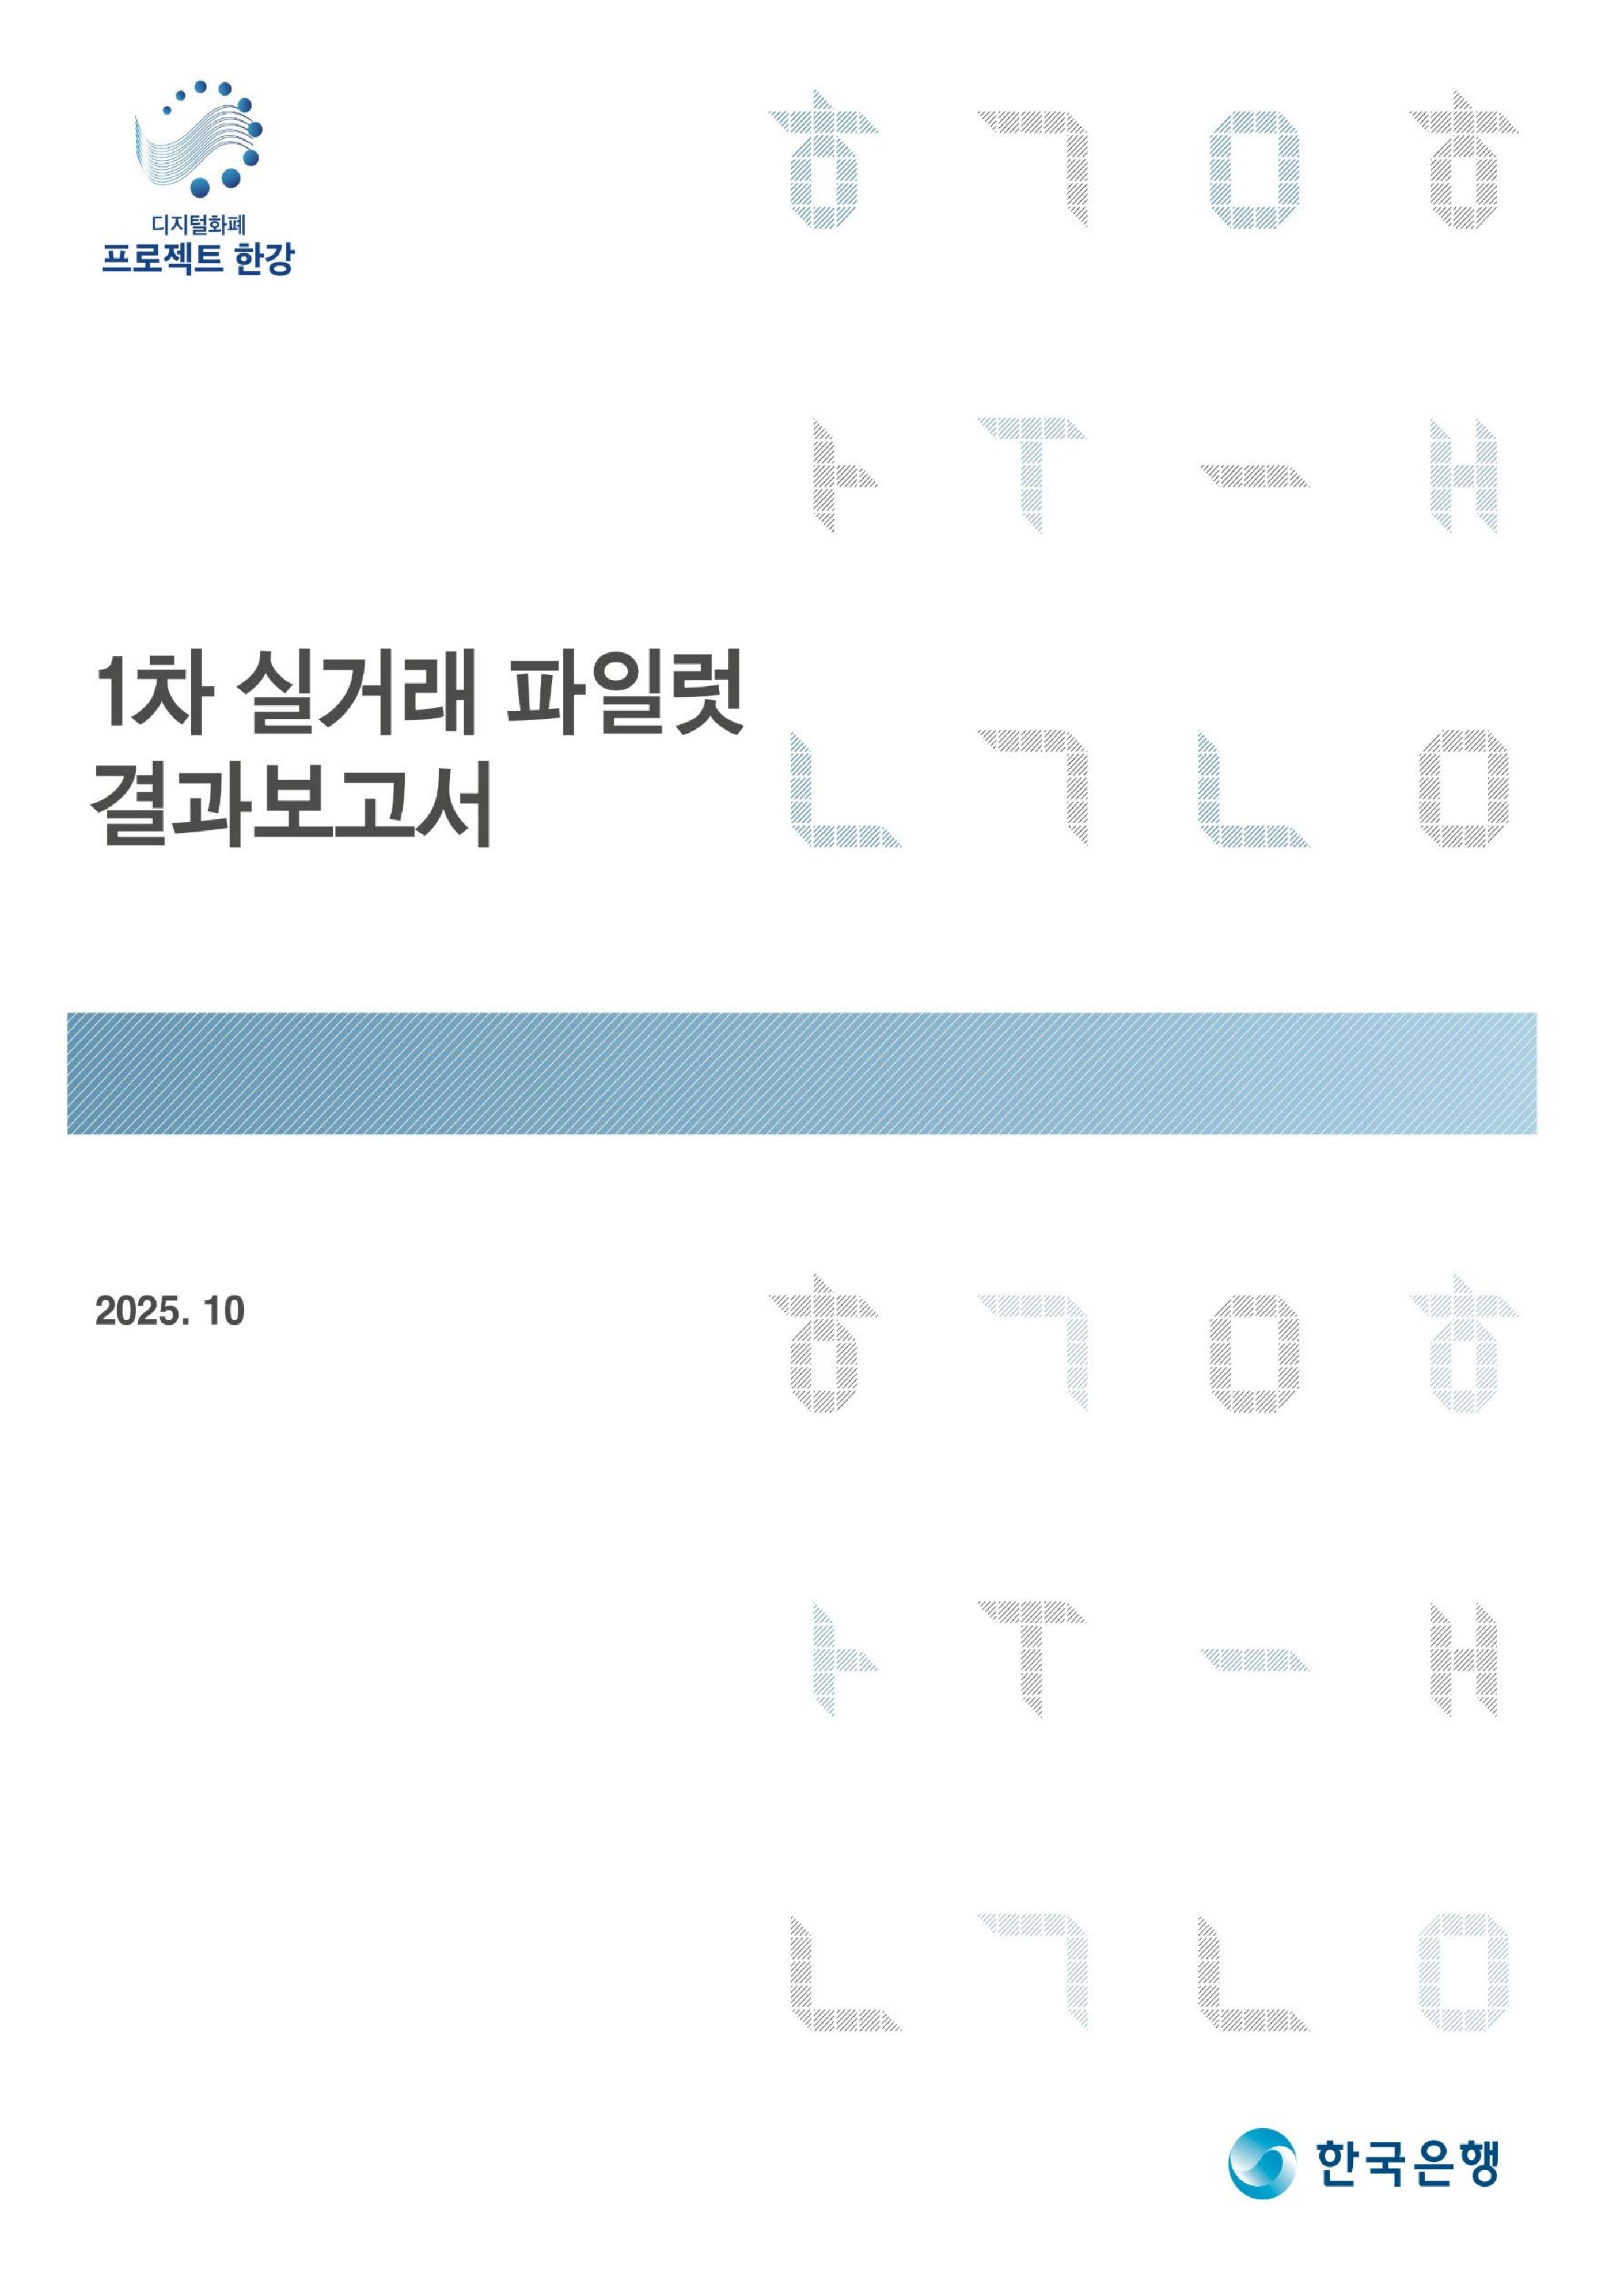

요약: 이 이미지는 "1차 실거래 파일럿 결과보고서"라는 제목의 문서 표지입니다. 아래에는 작성 년월이 2025년 10월로 표시되어 있으며, 한국은행의 로고도 포함되어 있습니다. 디자인은 현대적이며 깔끔한 느낌을 줍니다.

[1] figure-1-2.jpg


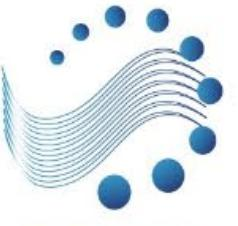

요약: 이 이미지는 특정한 로고 같아 보입니다. 하지만 어떤 기관이나 브랜드에 속하는 것인지 알 수 없습니다. 추가적인 정보를 제공해 주시면 더 도와드릴 수 있을 것 같습니다.



In [30]:
# ⌨️ 9-1. IPython.display 에서 Image, display 를 임포트합니다.
from IPython.display import Image, display


# ⌨️ 9-2. image_files 와 image_summaries 의 앞 3개를 zip + enumerate 로 반복하며
#        구분선, 번호와 파일 이름, 이미지(width=450), 요약문을 차례로 출력합니다.

for i , (img_file, summary) in enumerate(zip(image_files[:2], image_summaries[:2])):
    print("="*60)
    print(f"[{i}] {img_file.name}")
    print("="*60)
    display(Image(filename=str(img_file), width=450))
    print("요약:", summary)
    print()

**🗒️ 정리해 보기 (더블클릭해서 편집)**

- 내 요약의 수준 (나쁨 / 보통 / 좋음):
- 그렇게 판단한 이유:
- 개선하려면 프롬프트에 무엇을 추가할까:

> 💡 품질이 나쁘면 프롬프트에 **"축 이름, 수치 범위, 추세를 반드시 포함하세요"** 같은 지시를 추가해 보세요.

---
# Part 4. 마무리

## 10. 토큰 사용량 측정

### 📖 개념
- `tiktoken` = OpenAI 모델이 글자를 자르는 방식(토큰화)을 로컬에서 그대로 재현하는 도구
- **실제 비용 = 토큰 수 × 단가** (단가는 OpenAI 공식 가격 페이지에서 확인)
- 이미지 토큰은 해상도에 따라 달라 이 계산에 포함되지 않습니다.

In [31]:
# ⌨️ 10-1. tiktoken 을 임포트하고 "gpt-4o-mini" 용 인코더(enc)를 가져옵니다.

# ⌨️ 10-2. texts_2k_token 전체의 토큰 수 합 → input_tokens

# ⌨️ 10-3. text_summaries 전체의 토큰 수 합 → output_tokens

# ⌨️ 10-4. 입력 / 출력 / 합계 토큰(천 단위 콤마)과 요약한 이미지 수를 출력합니다.

import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o-mini")

input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("텍스트 요약 토큰 사용량 (추정)")
print(f"  입력 : {input_tokens:,} 토큰")
print(f"  출력 : {output_tokens:,} 토큰")
print(f"  합계 : {input_tokens + output_tokens:,} 토큰")
print()
print("요약한 이미지 수:", len(image_summaries), "장")
print()
print("※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.")
print("※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.")



텍스트 요약 토큰 사용량 (추정)
  입력 : 40,481 토큰
  출력 : 14,975 토큰
  합계 : 55,456 토큰

요약한 이미지 수: 50 장

※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.
※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.


## 11. 저장

### 📖 개념
요약 생성에도 **API 비용과 시간**이 듭니다. 다음 시간(벡터 저장소 구축)에서 바로 불러 쓰도록 저장합니다.

In [33]:
# ⌨️ 11-1. PROJECT_ROOT / "data" / "processed" 를 output_dir 로 잡고 폴더를 만듭니다. (parents, exist_ok)

# ⌨️ 11-2. output_dir / "summaries.pkl" 에 아래 4개 키를 가진 딕셔너리를 pickle.dump 합니다.
#         text_summaries, table_summaries, image_summaries, img_base64_list

# ⌨️ 11-3. 저장 경로를 출력합니다.

output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump(
        {
            "text_summaries": text_summaries,
            "table_summaries": table_summaries,
            "image_summaries": image_summaries,
            "img_base64_list": img_base64_list,
        },
        f,
    )

print("저장 완료:", output_dir / "summaries.pkl")
print("7교시에서 extracted.pkl 과 summaries.pkl 을 함께 불러옵니다.")

저장 완료: c:\workspaces\multimodal-rag\data\processed\summaries.pkl
7교시에서 extracted.pkl 과 summaries.pkl 을 함께 불러옵니다.


---

## ✅ 오늘의 체크포인트

- [ ] `text_summaries[0]`에 한국어 요약문이 출력된다
- [ ] `image_summaries[0]`에 그림을 설명하는 한국어 문장이 출력된다
- [ ] 그림과 요약문을 나란히 놓고 **육안으로 검증**했다
- [ ] `table_summaries`가 비어도 그 이유를 설명할 수 있다
- [ ] `data/processed/summaries.pkl` 파일이 생성되었다

## 💬 생각해 볼 질문 (더블클릭해서 편집)

**Q1. 이미지를 왜 굳이 텍스트로 요약할까요? 이미지 그대로 검색하면 안 되나요?**

답: 이미지를 텍스트로 요약하면 이미지에 담긴 내용을 검색에 활용 할 수 있기 때문입니다. 

**Q2. 요약문만 저장하고 원본은 버리면 어떤 문제가 생길까요?**

답: 요약문은 원본의 핵심 내용만 정리하기 때문에 세부 정보가 누락될 수 있습니다. 원본을 삭제하면 정확한 수치나 내용을 다시 확인할 수 없으므로 검색용 요약문과 원본 데이터를 함께 보관해야 합니다.

**Q3. `max_concurrency`를 100으로 올리면 어떤 일이 벌어질까요?**

답: 동시에 처리하는 요청 수가 증가하여 속도가 빨라질 수 있지만, API 요청이 과도하게 발생하면 ReteLimitError가 발생합니다.

## 🛠️ 자주 나는 에러

| 증상 | 원인 | 해결 |
| --- | --- | --- |
| `AuthenticationError` | `.env` 키 오타 / `load_dotenv()` 누락 | 키 앞뒤 공백·따옴표 제거 |
| `404 model not found` | 지원 종료된 모델명 사용 | `gpt-4o-mini` 사용 |
| `RateLimitError` | 동시 요청 과다 | `max_concurrency`를 5 → 2로 낮추기 |
| `FileNotFoundError: extracted.pkl` | 지난 시간 저장 셀 미실행 | 지난 노트북 마지막 셀 재실행 |
| `IndexError: list index out of range` | `figures/`에 이미지가 없음 | 1번 셀의 `figures_dir` 경로 확인 |
| 요약이 영어로 나옴 | 프롬프트에 한국어 지시 누락 | 프롬프트 마지막 줄 확인 |
| `NameError` | 앞 셀을 안 돌림 | 위에서부터 순서대로 재실행 |

> 그래도 안 되면 **커널 재시작 후 위에서부터 전체 재실행**하세요.

## ⏭️ 다음 시간 예고
오늘 만든 요약문을 **임베딩해 벡터 저장소(Chroma)에 넣고**, 요약으로 검색해 **원본**을 돌려주는 **멀티 벡터 검색기**를 만듭니다.